### Build a basic chatbot with langgraph (graph api)

In [1]:
from typing import Annotated

from typing_extensions import TypedDict 

from langgraph.graph import StateGraph, START, END 
from langgraph.graph.message import add_messages 

In [2]:
class State(TypedDict):
    messages: Annotated[list,add_messages]
    
graph_builder = StateGraph(State)

In [3]:
graph_builder

In [4]:
import os
from dotenv import load_dotenv

load_dotenv()


True

In [5]:
from langchain_openai import ChatOpenAI

custom_llm = ChatOpenAI(
    model="gemma-local",
    api_key=os.getenv("CHAT_API_KEY"),
    base_url=os.getenv("CHAT_API_BASE_URL"),
    temperature=0,
    verbose=True
)


In [6]:
## nODE fUNCTIONALITY
def chatbot(state: State) -> State:
    return {"messages": [custom_llm.invoke(state["messages"])]}

In [7]:
graph_builder = StateGraph(State)

# Adding node
graph_builder.add_node("llmchatbot", chatbot)
# Adding edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot", END)

graph = graph_builder.compile()

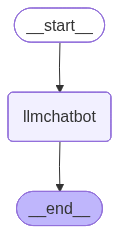

In [8]:
# visualise

from IPython.display import Image, display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [9]:
response = graph.invoke({"messages": ["Hello, how are you?"]})

In [10]:
response["messages"]

[HumanMessage(content='Hello, how are you?', additional_kwargs={}, response_metadata={}, id='ac5e264d-b883-4961-8e36-a42fa9c0bf83'),
 AIMessage(content="I'm doing well, thank you for asking! How are you doing today? Is there anything I can help you with?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 19, 'total_tokens': 46, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-ba855e7b98992c4f', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f3112-ea95-7af3-9264-45f95678bfcd-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 19, 'output_tokens': 27, 'total_tokens': 46, 'input_token_details': {}, 'output_token_details': {}})]

In [11]:
response["messages"][-1].content

"I'm doing well, thank you for asking! How are you doing today? Is there anything I can help you with?"

In [12]:
for event in graph.stream({"messages": ["Hello, how are you?"]}):
    print(event)

{'llmchatbot': {'messages': [AIMessage(content="I'm doing well, thank you for asking! How are you doing today? Is there anything I can help you with?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 19, 'total_tokens': 46, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-8323b7a3dc8fb105', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f3113-3496-7010-9173-98c003007bbe-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 19, 'output_tokens': 27, 'total_tokens': 46, 'input_token_details': {}, 'output_token_details': {}})]}}


In [13]:
for event in graph.stream({"messages": ["Hello, how are you?"]}):
    for value in event.values():
        print(value)

{'messages': [AIMessage(content="I'm doing well, thank you for asking! How are you doing today? Is there anything I can help you with?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 27, 'prompt_tokens': 19, 'total_tokens': 46, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-ac62ccd189a249e2', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f3113-3cda-73d2-bb6d-ad087e763f0f-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 19, 'output_tokens': 27, 'total_tokens': 46, 'input_token_details': {}, 'output_token_details': {}})]}


In [14]:
for event in graph.stream({"messages": ["Hello, how are you?"]}):
    for value in event.values():
        print(value["messages"][-1].content)

I'm doing well, thank you for asking! How are you doing today? Is there anything I can help you with?


Chatbot with tool usage

In [15]:
from langchain_tavily import TavilySearch

tool = TavilySearch(max_results=2)
tool.invoke("What is langgraph?")

{'query': 'What is langgraph?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.ibm.com/think/topics/langgraph',
   'title': 'What is LangGraph? | IBM',
   'content': 'LangGraph, created by LangChain, is an open source AI agent framework designed to build, deploy and manage complex generative AI agent workflows. It provides a set of tools and libraries that enable users to create, run and optimize large language models (LLMs) in a scalable and efficient manner. At its core, LangGraph uses the power of graph-based architectures to model and manage the intricate relationships between various components of an AI agent workflow. The following example can offer a clearer understanding of LangGraph: Think about these graph-based architectures as a powerful configurable map, a “Super-Map.” Users can envision the AI workflow as being “The Navigator” of this “Super-Map.” Finally, in this example, the user is “The Cartographer.” In this sense, the 

In [16]:
def multiply(a: int, b: int) -> int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: the product of a and b
    """
    return a * b

In [17]:
tools = [tool, multiply]

In [18]:
llm_with_tools=custom_llm.bind_tools(tools)

In [19]:
llm_with_tools

_ChatModelBinding(bound=ChatOpenAI(output_version=None, client=<openai.resources.chat.completions.completions.Completions object at 0x7e33137fc980>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x7e3313673080>, root_client=<openai.OpenAI object at 0x7e3313f43fb0>, root_async_client=<openai.AsyncOpenAI object at 0x7e3313ae5cd0>, model_name='gemma-local', temperature=0.0, model_kwargs={}, openai_api_key=SecretStr('**********'), openai_api_base='https://chat.soroco.com/api/v1', openai_proxy=None, stream_chunk_timeout=120.0), kwargs={'tools': [{'type': 'function', 'function': {'name': 'tavily_search', 'description': 'A search engine optimized for comprehensive, accurate, and trusted results. Useful for when you need to answer questions about current events. It not only retrieves URLs and snippets, but offers advanced search depths, domain management, time range filters, and image search, this tool delivers real-time, accurate, and citation-backed r

In [20]:
## State Graph with tools

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state: State) -> State:
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph 
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools", END)

graph = builder.compile()

In [21]:
from IPython.display import Image, display
try:
    display(Image(builder.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [22]:
response = graph.invoke({"messages": ["What is the recent ai news?, and use the TavilySearch tool to get latest news"]})

In [23]:
response

{'messages': [HumanMessage(content='What is the recent ai news?, and use the TavilySearch tool to get latest news', additional_kwargs={}, response_metadata={}, id='0fc20fe9-49dc-4cd1-bd16-d1051c9b4f14'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 47, 'prompt_tokens': 1482, 'total_tokens': 1529, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-bb98d70848424707', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019f3113-7bc9-7610-8c7a-b5de649e9bc8-0', tool_calls=[{'name': 'tavily_search', 'args': {'query': 'latest AI news October 2024', 'search_depth': 'advanced', 'time_range': 'week', 'topic': 'general'}, 'id': 'chatcmpl-tool-99d36a84fc47e51c', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 1482, 'output_tokens': 47, 'total_tokens': 1529, 'in

In [24]:
resp = graph.invoke({"messages": ["What is  2 multiply 3?"]})

In [25]:
resp

{'messages': [HumanMessage(content='What is  2 multiply 3?', additional_kwargs={}, response_metadata={}, id='40d4caaf-f52c-45eb-8453-15640ed94827'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 1472, 'total_tokens': 1487, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-b64ca79edc48109c', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019f3113-b007-77d3-94e3-327e4dd72eaf-0', tool_calls=[{'name': 'multiply', 'args': {'a': 2, 'b': 3}, 'id': 'chatcmpl-tool-b6f7e891d66bea08', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 1472, 'output_tokens': 15, 'total_tokens': 1487, 'input_token_details': {}, 'output_token_details': {}}),
  ToolMessage(content='6', name='multiply', id='0a5ebd07-a910-453d-85f8-89a0d2e89063', tool_call_id=

In [26]:
response= graph.invoke({"messages": ["give me recent ai news and What is  2 multiply 3?"]})

In [27]:
response

{'messages': [HumanMessage(content='give me recent ai news and What is  2 multiply 3?', additional_kwargs={}, response_metadata={}, id='7eacf5ad-d2a2-4996-aab5-587c834553ce'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 55, 'prompt_tokens': 1478, 'total_tokens': 1533, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-b0aba80fa95c3fa4', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019f3113-b5ec-7b80-a013-4db3be33be78-0', tool_calls=[{'name': 'tavily_search', 'args': {'query': 'latest AI news October 2024', 'search_depth': 'basic', 'time_range': 'week'}, 'id': 'chatcmpl-tool-85864e70d087a80b', 'type': 'tool_call'}, {'name': 'multiply', 'args': {'a': 2, 'b': 3}, 'id': 'chatcmpl-tool-8c36d261c1c3226f', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tok

### reACT architecture

In [39]:
## New graph which gets the llm response to itself 

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state: State) -> State:
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph 
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools", "tool_calling_llm")

graph = builder.compile()

In [40]:
from IPython.display import Image, display
try:
    display(Image(builder.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [41]:
response= graph.invoke({"messages": ["What is  2 multiply 3 and then multiply by 10 ?"]})

In [42]:
response

{'messages': [HumanMessage(content='What is  2 multiply 3 and then multiply by 10 ?', additional_kwargs={}, response_metadata={}, id='fc258ebb-6b5e-4e3c-ad40-d2048c220f38'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 1479, 'total_tokens': 1494, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-a71ac68b31ee34df', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019f3118-6606-7522-93e0-c3e90f846071-0', tool_calls=[{'name': 'multiply', 'args': {'a': 2, 'b': 3}, 'id': 'chatcmpl-tool-965022918a3ed95a', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 1479, 'output_tokens': 15, 'total_tokens': 1494, 'input_token_details': {}, 'output_token_details': {}}),
  ToolMessage(content='6', name='multiply', id='e3b4e86b-3be5-490a-b45b-b48

In [43]:
response["messages"][-1].content

'<|channel>thought\n<channel|>2 multiplied by 3 is 6, and 6 multiplied by 10 is 60.'

### Adding memory in Agentic Graph

In [44]:
response = graph.invoke({"messages": ["Hello my name is Gaurav"]})

for m in response["messages"]:
    print(m.content)

Hello my name is Gaurav
Hello Gaurav! It's nice to meet you. How can I help you today?


In [45]:
response = graph.invoke({"messages": ["What is my name ?"]})

for m in response["messages"]:
    print(m.content)

What is my name ?
I don't know your name because you haven't told me yet! Since I don't have access to your personal identity or private documents unless you share them with me in this conversation, I'm a stranger to you.

What is your name?


In [51]:
## New graph which gets the llm response to itself 

from langgraph.graph import StateGraph, START, END
from langgraph.graph.message import add_messages
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory_saver = MemorySaver()

## Node definition
def tool_calling_llm(state: State) -> State:
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

## Graph 
builder = StateGraph(State)
builder.add_node("tool_calling_llm", tool_calling_llm)
builder.add_node("tools", ToolNode(tools))

builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges("tool_calling_llm", tools_condition)
builder.add_edge("tools", "tool_calling_llm")

graph = builder.compile(checkpointer=memory_saver)

In [52]:
config = {"configurable": {"thread_id": "1"}}

response = graph.invoke({"messages": ["Hello my name is Gaurav"]}, config=config)

response

{'messages': [HumanMessage(content='Hello my name is Gaurav', additional_kwargs={}, response_metadata={}, id='1abb503c-597f-45f6-a379-af6a34f40ac5'),
  AIMessage(content="Hello Gaurav! It's nice to meet you. How can I help you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 20, 'prompt_tokens': 1470, 'total_tokens': 1490, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-b3666ee7daf2a71e', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f311b-4853-7ac0-8e23-e36159a7c8e9-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1470, 'output_tokens': 20, 'total_tokens': 1490, 'input_token_details': {}, 'output_token_details': {}})]}

In [53]:
response["messages"][-1].content

"Hello Gaurav! It's nice to meet you. How can I help you today?"

In [54]:
response = graph.invoke({"messages": ["What is my name ?"]}, config=config)

In [55]:
response

{'messages': [HumanMessage(content='Hello my name is Gaurav', additional_kwargs={}, response_metadata={}, id='1abb503c-597f-45f6-a379-af6a34f40ac5'),
  AIMessage(content="Hello Gaurav! It's nice to meet you. How can I help you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 20, 'prompt_tokens': 1470, 'total_tokens': 1490, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-b3666ee7daf2a71e', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f311b-4853-7ac0-8e23-e36159a7c8e9-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1470, 'output_tokens': 20, 'total_tokens': 1490, 'input_token_details': {}, 'output_token_details': {}}),
  HumanMessage(content='What is my name ?', additional_kwargs={}, response_metadata={}, id='dd4d49a6-b374-4db2-b911-10298df6620e'),
  AIMessage(conten

In [56]:
response["messages"][-1].content

'Your name is Gaurav.'

In [57]:
response = graph.invoke({"messages": ["do you remember my name ?"]}, config=config)

In [58]:
response

{'messages': [HumanMessage(content='Hello my name is Gaurav', additional_kwargs={}, response_metadata={}, id='1abb503c-597f-45f6-a379-af6a34f40ac5'),
  AIMessage(content="Hello Gaurav! It's nice to meet you. How can I help you today?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 20, 'prompt_tokens': 1470, 'total_tokens': 1490, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-b3666ee7daf2a71e', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f311b-4853-7ac0-8e23-e36159a7c8e9-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1470, 'output_tokens': 20, 'total_tokens': 1490, 'input_token_details': {}, 'output_token_details': {}}),
  HumanMessage(content='What is my name ?', additional_kwargs={}, response_metadata={}, id='dd4d49a6-b374-4db2-b911-10298df6620e'),
  AIMessage(conten

In [59]:
config2 = {"configurable": {"thread_id": "2"}}
response = graph.invoke({"messages": ["do you remember my name ?"]}, config=config2)

In [60]:
response

{'messages': [HumanMessage(content='do you remember my name ?', additional_kwargs={}, response_metadata={}, id='2fb39cb1-6ba0-4986-88a3-97617d135fce'),
  AIMessage(content="I don't have a memory of our past conversations, so I don't know your name unless you told me earlier in this specific chat. \n\nWhat is your name?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 38, 'prompt_tokens': 1470, 'total_tokens': 1508, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-87f0e0c420ca4584', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f311f-7a89-7a83-9928-bb57c341b2ee-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1470, 'output_tokens': 38, 'total_tokens': 1508, 'input_token_details': {}, 'output_token_details': {}})]}

### Streaming

In [64]:
from langgraph.checkpoint.memory import MemorySaver
memory = MemorySaver()

In [65]:
def superbot(state: State) -> State:
    return {"messages": [llm_with_tools.invoke(state["messages"])]}

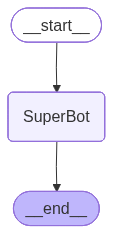

In [66]:
graph = StateGraph(State)

## node
graph.add_node("SuperBot", superbot)
## Edges

graph.add_edge(START, "SuperBot")
graph.add_edge("SuperBot", END)


graph_builder = graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))


In [67]:
config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({"messages": ["Hello my name is Gaurav and I play badminton"]}, config=config)

{'messages': [HumanMessage(content='Hello my name is Gaurav and I play badminton', additional_kwargs={}, response_metadata={}, id='88fe28db-5d6e-4d90-ae15-e797aa4fcf1c'),
  AIMessage(content="Hello Gaurav! It's nice to meet you. \n\nBadminton is a fantastic sport—it requires a great mix of speed, agility, and strategy. Do you play competitively, or is it more of a hobby for you? Also, do you prefer playing singles or doubles?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 60, 'prompt_tokens': 1474, 'total_tokens': 1534, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-8b7301ec79386350', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f3123-e7c7-7ac1-95ed-a5e17bd7aa34-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1474, 'output_tokens': 60, 'total_tokens': 1534, 'input_toke

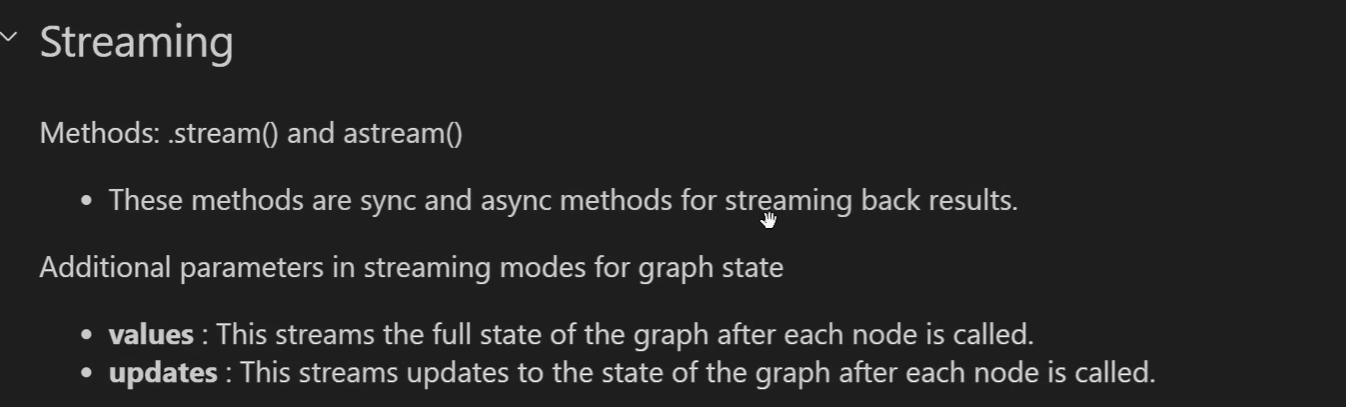

In [68]:
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({"messages":"Hi, My name is Gaurav and I like Badminton"},config, stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content="Nice to meet you, Gaurav! It's great that you enjoy badminton. It's a fantastic sport for agility and reflexes.\n\nDo you play competitively, or is it more of a hobby for you? Also, do you have a favorite professional player you look up to, like Viktor Axelsen or Tai Tzu-ying?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 69, 'prompt_tokens': 1475, 'total_tokens': 1544, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-923f610201129bed', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f312e-cdb3-7972-bc2b-f8fa2a1808cc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1475, 'output_tokens': 69, 'total_tokens': 1544, 'input_token_details': {}, 'output_token_details': {}})]}}


In [69]:
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({"messages":"Hi, My name is Gaurav and I like Badminton"},config, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi, My name is Gaurav and I like Badminton', additional_kwargs={}, response_metadata={}, id='1c0b1fbd-97c0-4a93-a862-ef5c6a8e1164'), AIMessage(content="Nice to meet you, Gaurav! It's great that you enjoy badminton. It's a fantastic sport for agility and reflexes.\n\nDo you play competitively, or is it more of a hobby for you? Also, do you have a favorite professional player you look up to, like Viktor Axelsen or Tai Tzu-ying?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 69, 'prompt_tokens': 1475, 'total_tokens': 1544, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-923f610201129bed', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f312e-cdb3-7972-bc2b-f8fa2a1808cc-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1475, 'output_tokens': 6

In [71]:
config4 = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({"messages":"Hi, My name is Gaurav and I like Badminton"},config4, stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content="It looks like you've sent that again! Nice to meet you (once more), Gaurav. \n\nSince you like badminton, I'm curious:\n*   Do you prefer **singles or doubles**?\n*   Are you more of a **power hitter** (smash specialist) or a **tactical player** (drop shots and net play)?\n*   Or are you just getting started with the sport?\n\nLet me know if you want to talk about gear, training tips, or the latest tournaments!", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 111, 'prompt_tokens': 1564, 'total_tokens': 1675, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-ace0068a198679f9', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f3138-e526-7e90-839e-81f6930254f6-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1564, 'output_tokens': 111, 

In [72]:
# config4 = {"configurable": {"thread_id": "4"}}

for chunk in graph_builder.stream({"messages":"I also like football"},config4, stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi, My name is Gaurav and I like Badminton', additional_kwargs={}, response_metadata={}, id='60871a33-695a-4e78-9e8a-53475c54a554'), AIMessage(content="Nice to meet you, Gaurav! It's great that you enjoy badminton. It's a fantastic sport for agility and reflexes.\n\nDo you play competitively, or is it more of a hobby for you? Also, do you have a favorite professional player you look up to, like Viktor Axelsen or Tai Tzu-ying?", additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 69, 'prompt_tokens': 1475, 'total_tokens': 1544, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-9d8c6299850bd337', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f3138-9f85-75a0-9801-ca9df197aae4-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 1475, 'output_tokens': 6

In [74]:
config5 = {"configurable": {"thread_id": "5"}}
async for event in graph_builder.astream_events({"messages":"My name is gaurav and i like football"},config5, stream_mode="values"):
    print(event)

{'event': 'on_chain_start', 'data': {'input': {'messages': 'My name is gaurav and i like football'}}, 'name': 'LangGraph', 'tags': [], 'run_id': '019f313c-0a8c-7e42-ad9e-a6132caa9555', 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'parent_ids': []}
{'event': 'on_chain_stream', 'run_id': '019f313c-0a8c-7e42-ad9e-a6132caa9555', 'name': 'LangGraph', 'tags': [], 'metadata': {'thread_id': '5', 'ls_integration': 'langgraph'}, 'data': {'chunk': {'messages': [HumanMessage(content='My name is gaurav and i like football', additional_kwargs={}, response_metadata={}, id='48f9dc8f-c0b4-4fa9-ae30-d940b0bfd6c4')]}}, 'parent_ids': []}
{'event': 'on_chain_start', 'data': {'input': {'messages': [HumanMessage(content='My name is gaurav and i like football', additional_kwargs={}, response_metadata={}, id='48f9dc8f-c0b4-4fa9-ae30-d940b0bfd6c4')]}}, 'name': 'SuperBot', 'tags': ['graph:step:1'], 'run_id': '019f313c-0a93-7d00-9c8b-c4bf476cb53b', 'metadata': {'thread_id': '5', 'ls_integration'